# Machine Learning CCN PROJECT
**Eugène LALLAIN Abdou-Samad Darfilal Ambroise Couturier Paul Mahaut**

**Plan**
1. Introduction to CNNs
2. Dataset exploration (80/20 train/test split)
3. Build the CNN
4. Train the model
5. Evaluate on the test set
6. Improve the model (data augmentation, dropout + batch normalization)
7. Final comparison

## Step 1 - Introduction to CNNs

A Convolutional Neural Network (CNN) is a neural network designed for images. Instead of looking at every pixel independently, it slides small filters over the image to detect local patterns (edges, textures, then shapes, then whole objects).

In [2]:
#%pip install scikit-learn

In [3]:
import os, sys, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

Python: 3.13.1
TensorFlow: 2.21.0


## Step 2 - Dataset Exploration



In [4]:
DATA_DIR = "cats_and_dogs_filtered"
train_dir = os.path.join(DATA_DIR, "train")
validation_dir = os.path.join(DATA_DIR, "validation")

for class_name in ["cats", "dogs"]:
    n_train = len(os.listdir(os.path.join(train_dir, class_name)))
    n_val = len(os.listdir(os.path.join(validation_dir, class_name)))
    print(f"{class_name}: training = {n_train}, validation = {n_val}")

cats: training = 1000, validation = 500
dogs: training = 1000, validation = 500


The dataset should contain 1,000 training and 500 validation images per class. The classes are **balanced** (same number of cats and dogs), so plain accuracy is a fair metric and no re-weighting is needed.

In [5]:
shapes = []
for class_name in ["cats", "dogs"]:
    folder = os.path.join(train_dir, class_name)
    for filename in os.listdir(folder):
        with Image.open(os.path.join(folder, filename)) as img:
            shapes.append((img.height, img.width, len(img.getbands())))
shapes = np.array(shapes)
print("Mean (height, width, channels):", shapes.mean(axis=0).round(1))
print("Min  (height, width, channels):", shapes.min(axis=0))
print("Max  (height, width, channels):", shapes.max(axis=0))

Mean (height, width, channels): [358.9 404.    3. ]
Min  (height, width, channels): [50 59  3]
Max  (height, width, channels): [ 768 1023    3]


Images have different sizes (and a few may not be RGB). A CNN needs a fixed input size, so we will convert everything to RGB and resize it to one common size.

### Visualize some images

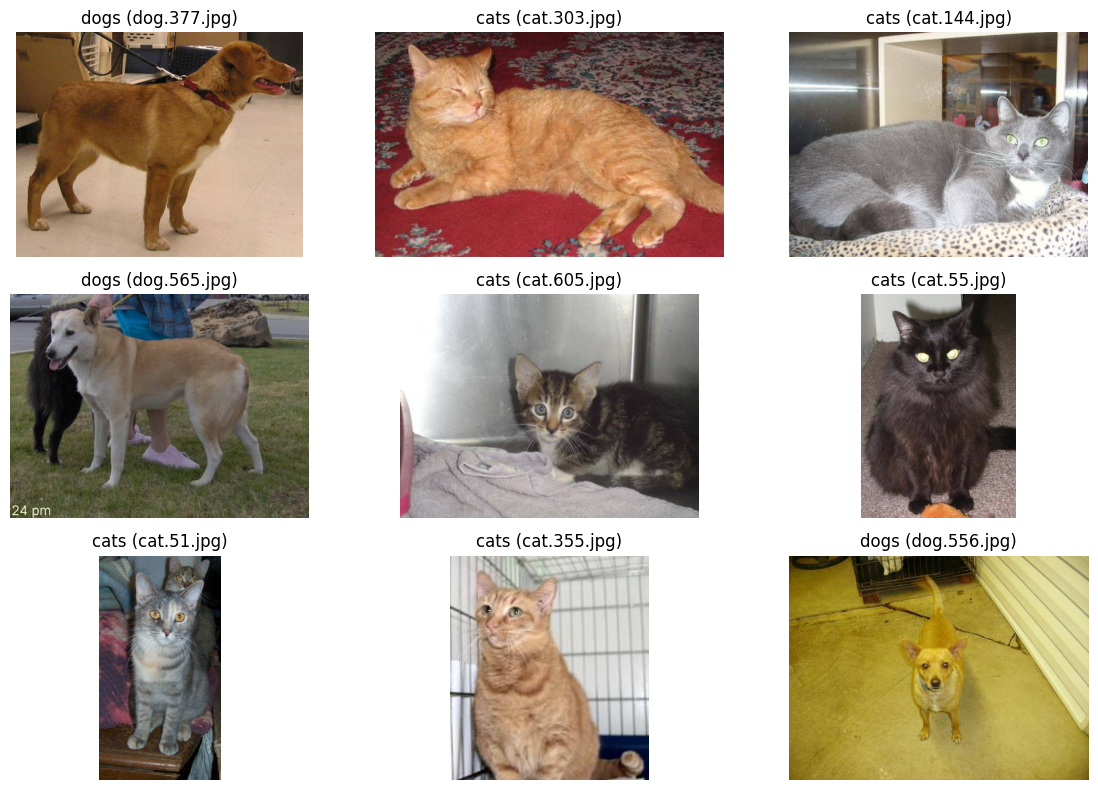

In [6]:
all_files = []
for class_name in ["cats", "dogs"]:
    folder = os.path.join(train_dir, class_name)
    for filename in os.listdir(folder):
        all_files.append((os.path.join(folder, filename), class_name))

plt.figure(figsize=(12, 8))
for i, (path, label) in enumerate(random.sample(all_files, 9)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(Image.open(path))
    plt.title(f"{label} ({os.path.basename(path)})")
    plt.axis("off")
plt.tight_layout()
plt.show()

### Train / test split (80% - 20%)

As requested, we split the training folder into 80% training and 20% test. The dataset's own validation folder is kept as our validation set, used during training to monitor the NN.

In [7]:
df = pd.DataFrame(all_files, columns=["filepath", "label"])

train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df["label"], random_state=SEED
)

print("Train:", len(train_df), "| Test:", len(test_df))
print(train_df["label"].value_counts().to_dict(), test_df["label"].value_counts().to_dict())

Train: 1600 | Test: 400
{'dogs': 800, 'cats': 800} {'cats': 200, 'dogs': 200}


### Load and preprocess images

ImageDataGenerator loads images in batches, resizes them to a fixed size and rescales pixel values from [0, 255] to [0, 1]. Batch size is 100. 

In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (150, 150)
BATCH_SIZE = 100
EPOCHS = 7             

def make_train_gen(datagen):
    return datagen.flow_from_dataframe(
        train_df, x_col="filepath", y_col="label",
        target_size=IMG_SIZE, color_mode="rgb",
        batch_size=BATCH_SIZE, class_mode="binary",
        shuffle=True, seed=SEED)

plain_datagen = ImageDataGenerator(rescale=1.0 / 255)

train_gen = make_train_gen(plain_datagen)

val_gen = plain_datagen.flow_from_directory(
    validation_dir, target_size=IMG_SIZE, color_mode="rgb",
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=False)

test_gen = plain_datagen.flow_from_dataframe(
    test_df, x_col="filepath", y_col="label",
    target_size=IMG_SIZE, color_mode="rgb",
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=False)

print("Input shape:", train_gen.image_shape)
print("Class mapping:", train_gen.class_indices, "-> output = probability of 'dogs'")

Found 1600 validated image filenames belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Found 400 validated image filenames belonging to 2 classes.
Input shape: (150, 150, 3)
Class mapping: {'cats': 0, 'dogs': 1} -> output = probability of 'dogs'


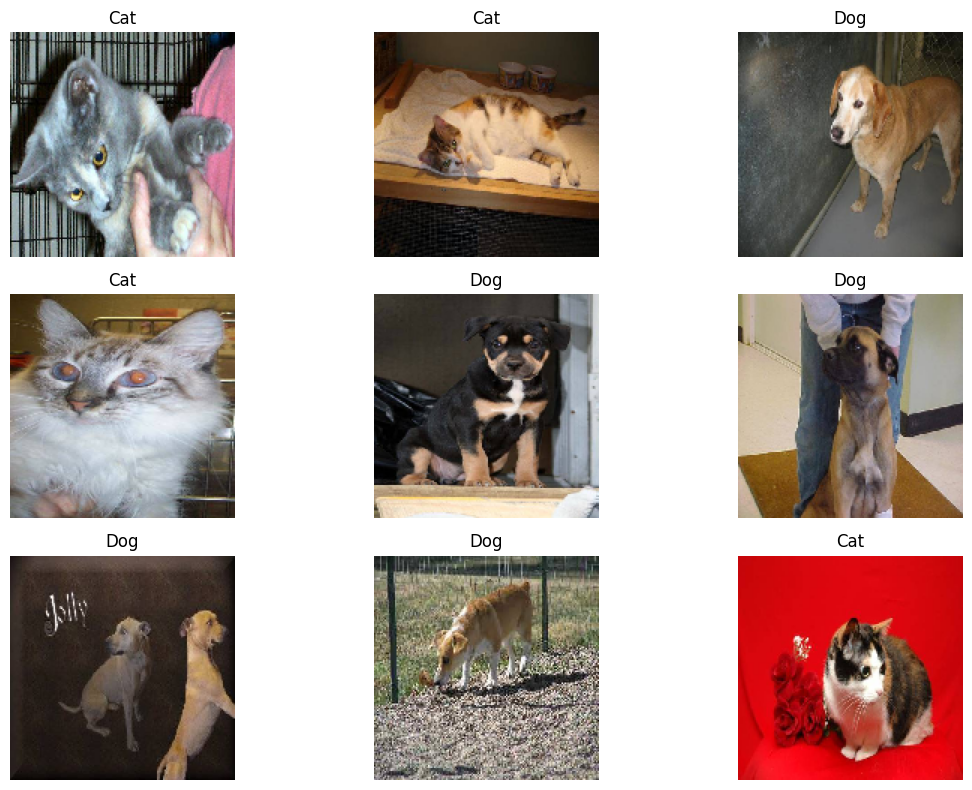

In [9]:

images, labels = next(train_gen)
plt.figure(figsize=(12, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i])
    plt.title("Dog" if labels[i] == 1 else "Cat")
    plt.axis("off")
plt.tight_layout()
plt.show()

## Step 3 - Build the CNN

In [10]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

def build_cnn(use_dropout_bn=False):
    layers = [Input(shape=(*IMG_SIZE, 3))]

    for filters in [32, 64, 128, 128]:          
        layers.append(Conv2D(filters, (3, 3), activation="relu"))
        if use_dropout_bn:
            layers.append(BatchNormalization())
        layers.append(MaxPooling2D((2, 2)))

    layers.append(Flatten())
    if use_dropout_bn:
        layers.append(Dropout(0.5))
    layers.append(Dense(128, activation="relu"))
    layers.append(Dense(1, activation="sigmoid")) 

    model = Sequential(layers)
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

model = build_cnn()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,043,905 (3.98 MB)

 Trainable params: 1,043,905 (3.98 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
conv = lambda k, c_in, f: (k * k * c_in + 1) * f
dense = lambda n_in, n: (n_in + 1) * n

size = IMG_SIZE[0]
for _ in range(4):
    size = (size - 2) // 2
flat = size * size * 128

manual_total = (conv(3, 3, 32) + conv(3, 32, 64) + conv(3, 64, 128) + conv(3, 128, 128)
                + dense(flat, 128) + dense(128, 1))

print("Flatten size:", flat)
print("Manual total  :", f"{manual_total:,}")
print("Keras total   :", f"{model.count_params():,}")
assert manual_total == model.count_params()

Flatten size: 6272
Manual total  : 1,043,905
Keras total   : 1,043,905


## Step 4 - Train the Model

In [12]:
from tensorflow.keras.callbacks import EarlyStopping

def train(model, train_data, val_data=None):
    val_data = val_data if val_data is not None else val_gen
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    return model.fit(train_data, epochs=EPOCHS, validation_data=val_data,
                     callbacks=[early_stopping])

def plot_history(history, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        ax.plot(history.history[metric], label=f"Training {metric}")
        ax.plot(history.history[f"val_{metric}"], label=f"Validation {metric}")
        ax.set_xlabel("Epoch"); ax.set_ylabel(metric.capitalize()); ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def diagnose(history):
    tr, va = history.history["accuracy"][-1], history.history["val_accuracy"][-1]
    print(f"Final training accuracy  : {tr:.3f}")
    print(f"Final validation accuracy: {va:.3f}")
    print(f"Gap (train - val)        : {tr - va:.3f}")


history = train(model, train_gen)

Epoch 1/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.4844 - loss: 0.6974 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 2/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 872ms/step - accuracy: 0.5013 - loss: 0.6927 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 3/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 830ms/step - accuracy: 0.4750 - loss: 0.6924 - val_accuracy: 0.5000 - val_loss: 0.6835
Epoch 4/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 839ms/step - accuracy: 0.5744 - loss: 0.6769 - val_accuracy: 0.6290 - val_loss: 0.6455
Epoch 5/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 782ms/step - accuracy: 0.5594 - loss: 0.6806 - val_accuracy: 0.5010 - val_loss: 0.6895
Epoch 6/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 775ms/step - accuracy: 0.5469 - loss: 0.6856 - val_accuracy: 0.5490 - val_loss: 0.6836
Epoch 7/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 776ms/step - accuracy: 0.5669 - loss: 0.6749 - val_accuracy: 0.5730 - val_loss: 0.6771


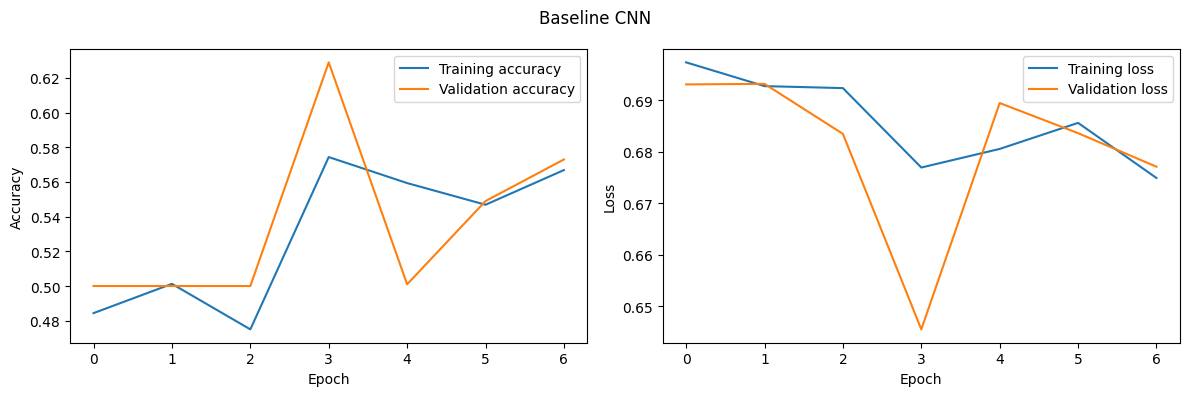

Final training accuracy  : 0.567
Final validation accuracy: 0.573
Gap (train - val)        : -0.006


In [13]:
plot_history(history, "Baseline CNN")
diagnose(history)

## Step 5 - Evaluate the Model on the Test Set

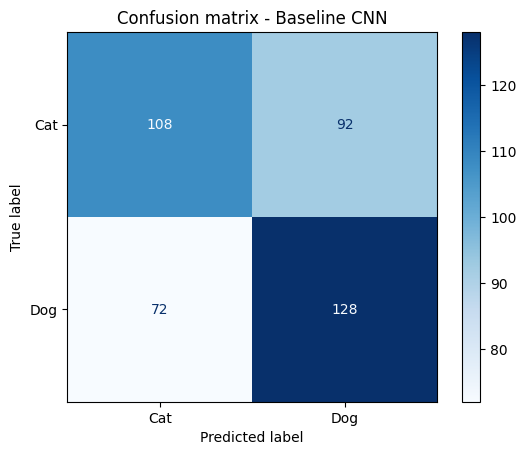

Accuracy  : 0.590
Precision : 0.582
Recall    : 0.640
F1-score  : 0.610


In [14]:
results = []

def evaluate(model, name, data=None):
    data = data if data is not None else test_gen
    probs = model.predict(data, verbose=0).ravel()
    y_pred = (probs > 0.5).astype(int)
    y_true = data.classes            

    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Cat", "Dog"]).plot(cmap="Blues")
    plt.title(f"Confusion matrix - {name}")
    plt.show()

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
    }
    for k, v in metrics.items():
        if k != "Model":
            print(f"{k:10s}: {v:.3f}")
    results.append(metrics)

evaluate(model, "Baseline CNN")

## Step 6 - Improve the Model

Found 1600 validated image filenames belonging to 2 classes.
Found 2 validated image filenames belonging to 2 classes.


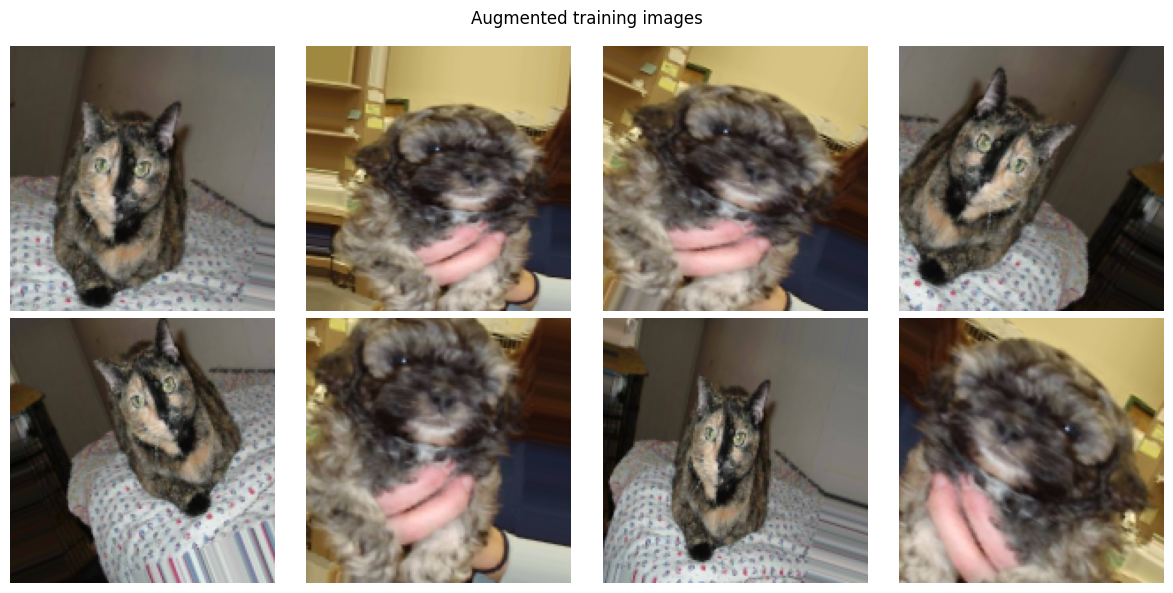

In [15]:
aug_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=30,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode="nearest",
)
aug_train_gen = make_train_gen(aug_datagen)

sample = train_df.groupby("label", group_keys=False).head(1)
preview = aug_datagen.flow_from_dataframe(
    sample,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    class_mode="binary",
    batch_size=1,
    shuffle=True
)

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(next(preview)[0][0])
    plt.axis("off")
plt.suptitle("Augmented training images")
plt.tight_layout()
plt.show()

Epoch 1/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.4806 - loss: 0.6978 - val_accuracy: 0.5020 - val_loss: 0.6924
Epoch 2/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.5013 - loss: 0.6929 - val_accuracy: 0.5360 - val_loss: 0.6918
Epoch 3/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.5619 - loss: 0.6909 - val_accuracy: 0.6480 - val_loss: 0.6848
Epoch 4/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.5594 - loss: 0.6863 - val_accuracy: 0.5030 - val_loss: 0.6920
Epoch 5/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.5694 - loss: 0.6801 - val_accuracy: 0.5830 - val_loss: 0.6653
Epoch 6/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.5956 - loss: 0.6631 - val_accuracy: 0.6400 - val_loss: 0.6385
Epoch 7/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.6469 - loss: 0.6314 - val_accuracy: 0.6730 - val_loss: 0.5983


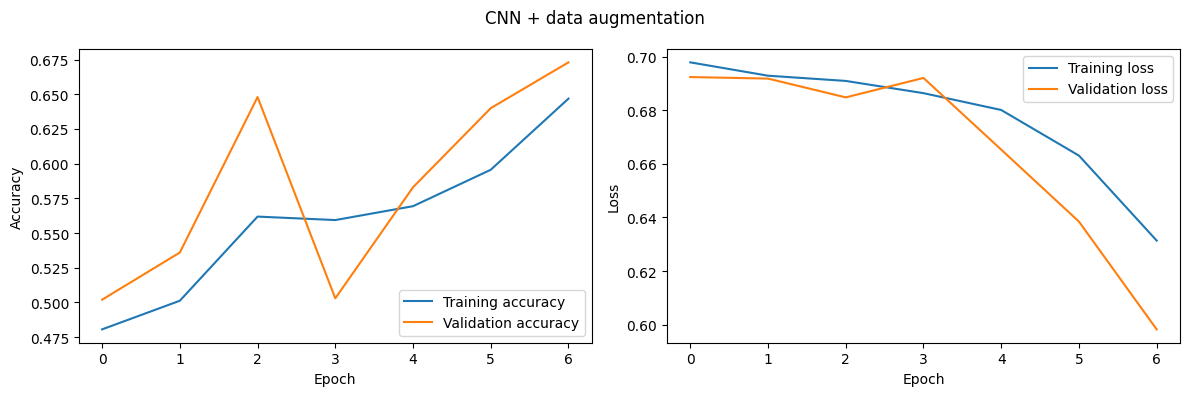

Final training accuracy  : 0.647
Final validation accuracy: 0.673
Gap (train - val)        : -0.026


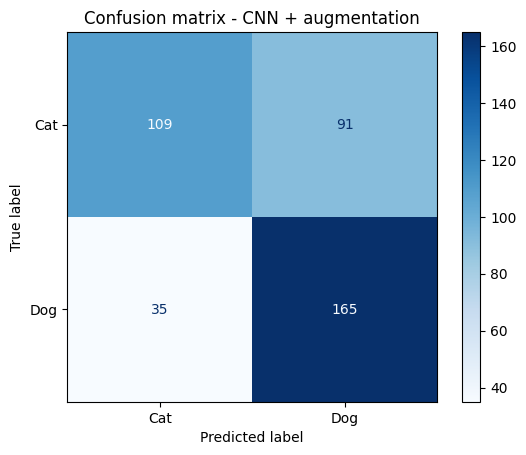

Accuracy  : 0.685
Precision : 0.645
Recall    : 0.825
F1-score  : 0.724


In [16]:
model_aug = build_cnn()
history_aug = train(model_aug, aug_train_gen)
plot_history(history_aug, "CNN + data augmentation")
diagnose(history_aug)
evaluate(model_aug, "CNN + augmentation")

Epoch 1/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.5450 - loss: 1.2577 - val_accuracy: 0.4800 - val_loss: 0.7760
Epoch 2/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.6562 - loss: 0.6205 - val_accuracy: 0.5200 - val_loss: 0.7692
Epoch 3/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.7287 - loss: 0.5368 - val_accuracy: 0.5220 - val_loss: 0.7912
Epoch 4/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.7850 - loss: 0.4475 - val_accuracy: 0.5560 - val_loss: 0.7094
Epoch 5/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.8419 - loss: 0.3718 - val_accuracy: 0.5050 - val_loss: 0.7918
Epoch 6/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.8537 - loss: 0.3294 - val_accuracy: 0.5010 - val_loss: 0.9366
Epoch 7/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.8919 - loss: 0.2640 - val_accuracy: 0.5000 - val_loss: 1.7195


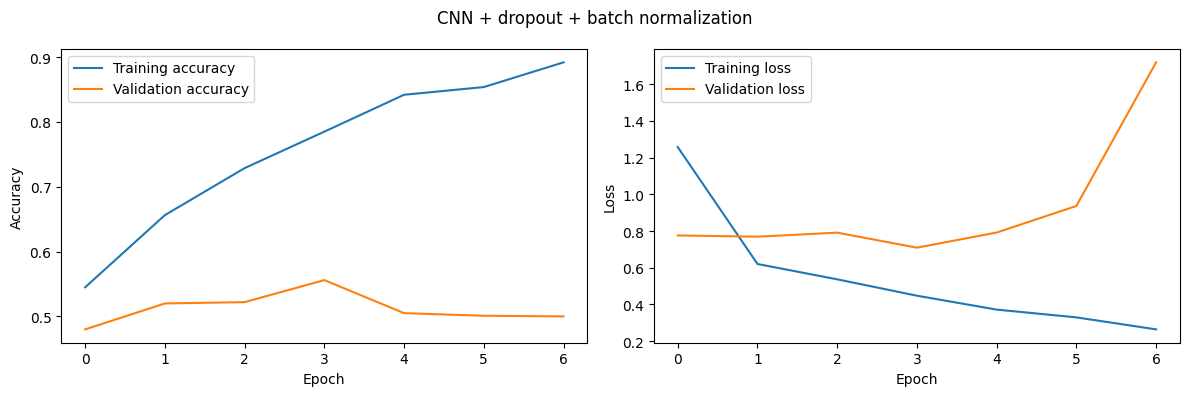

Final training accuracy  : 0.892
Final validation accuracy: 0.500
Gap (train - val)        : 0.392


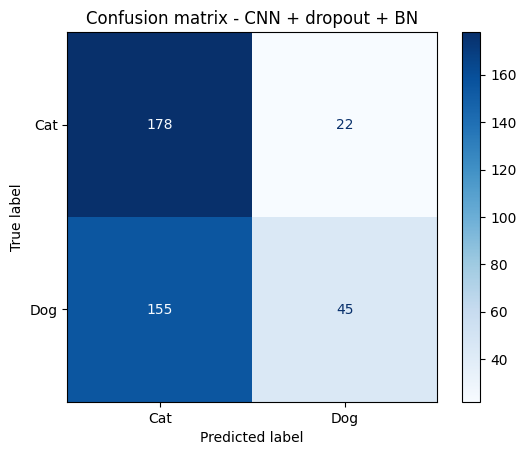

Accuracy  : 0.557
Precision : 0.672
Recall    : 0.225
F1-score  : 0.337


In [17]:
model_dbn = build_cnn(use_dropout_bn=True)
history_dbn = train(model_dbn, train_gen)
plot_history(history_dbn, "CNN + dropout + batch normalization")
diagnose(history_dbn)
evaluate(model_dbn, "CNN + dropout + BN")

## Final Comparison

,Accuracy,Precision,Recall,F1-score
Model,,,,
Baseline CNN,0.590,0.582,0.640,0.610
CNN + augmentation,0.685,0.645,0.825,0.724
CNN + dropout + BN,0.558,0.672,0.225,0.337


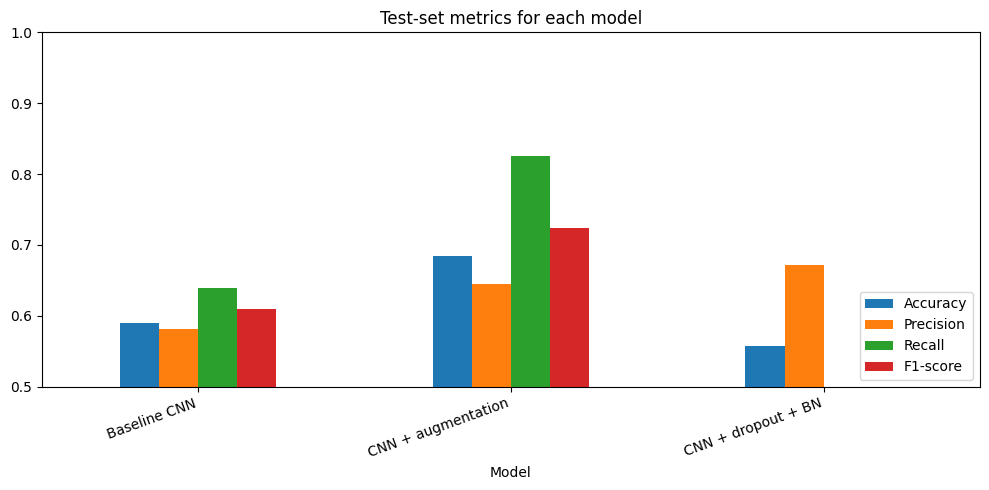

In [18]:
comparison = pd.DataFrame(results).set_index("Model").round(3)
display(comparison)

comparison.plot(kind="bar", figsize=(10, 5), ylim=(0.5, 1.0))
plt.title("Test-set metrics for each model")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()